In [ ]:

# STEP 1: Download the original OULAD dataset

import os
import requests
import zipfile

# Create a folder for original, unclean data
os.makedirs("/content/oulad_raw", exist_ok=True)

# Official UCI dataset download
url = "https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip"

zip_path = "/content/oulad_dataset.zip"

print("Downloading original dataset...")

response = requests.get(url, stream=True, timeout=180)
response.raise_for_status()

with open(zip_path, "wb") as file:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            file.write(chunk)

print("Download completed!")

# Extract original files
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/oulad_raw")

print("Dataset extracted successfully!")

# Display downloaded files
print("\nDownloaded files:")

for root, dirs, files in os.walk("/content/oulad_raw"):
    for filename in files:
        file_path = os.path.join(root, filename)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"{filename} - {size_mb:.2f} MB")


In [1]:

# STEP 2: Import libraries and load all CSV files

import pandas as pd
import numpy as np
import os
import glob

# Find all CSV files inside the extracted folder
csv_files = glob.glob("/content/oulad_raw/**/*.csv", recursive=True)

print("Total CSV files found:", len(csv_files))

# Load all CSV files into a dictionary
datasets = {}

for file in csv_files:
    file_name = os.path.basename(file).replace(".csv", "")
    datasets[file_name] = pd.read_csv(file)

    print(f"\nLoaded: {file_name}")
    print("Rows and Columns:", datasets[file_name].shape)

print("\nAll datasets loaded successfully!")


Total CSV files found: 0

All datasets loaded successfully!


In [2]:

# STEP 3: Dataset overview

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("DATASET:", name)
    print("=" * 60)

    print("\nNumber of Rows:", df.shape[0])
    print("Number of Columns:", df.shape[1])

    print("\nFirst 5 Records:")
    display(df.head())

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)


In [3]:

# STEP 4: Data quality inspection

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("DATA QUALITY:", name)
    print("=" * 60)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nTotal Missing Values:", df.isnull().sum().sum())

    print("\nExact Duplicate Rows:", df.duplicated().sum())

    print("\nStatistical Summary:")
    display(df.describe(include="all").T)


In [4]:

# STEP 5: Complete Data Audit

audit_results = []

for name, df in datasets.items():

    for column in df.columns:

        audit_results.append({
            "Dataset": name,
            "Column": column,
            "Data Type": str(df[column].dtype),
            "Total Rows": len(df),
            "Missing Values": df[column].isnull().sum(),
            "Missing Percentage": round(
                df[column].isnull().mean() * 100, 2
            ),
            "Unique Values": df[column].nunique(),
            "Duplicate Rows": df.duplicated().sum()
        })

audit_df = pd.DataFrame(audit_results)

print("COMPLETE DATA AUDIT REPORT")
display(audit_df)

# Save audit report
audit_df.to_csv(
    "/content/data_audit_report.csv",
    index=False
)

print("Audit report saved successfully!")


COMPLETE DATA AUDIT REPORT


""


Audit report saved successfully!


In [5]:

# STEP 6: Create Data Dictionary

dictionary = []

for name, df in datasets.items():

    for column in df.columns:

        if pd.api.types.is_numeric_dtype(df[column]):
            category = "Numerical"
        else:
            category = "Categorical / Text"

        dictionary.append({
            "Dataset": name,
            "Column Name": column,
            "Data Type": str(df[column].dtype),
            "Variable Category": category,
            "Unique Values": df[column].nunique(),
            "Example Value": (
                df[column].dropna().iloc[0]
                if not df[column].dropna().empty
                else "No Data"
            )
        })

data_dictionary = pd.DataFrame(dictionary)

print("DATA DICTIONARY")
display(data_dictionary)

# Save dictionary
data_dictionary.to_csv(
    "/content/data_dictionary.csv",
    index=False
)

print("Data dictionary saved successfully!")


DATA DICTIONARY


""


Data dictionary saved successfully!


In [10]:

# CHECK DATASET NAMES

print("Available dataset names:")

for name in datasets.keys():
    print(name)


Available dataset names:


In [11]:

# RELOAD ALL CSV FILES

import pandas as pd
import os
import glob

csv_files = glob.glob(
    "/content/oulad_raw/**/*.csv",
    recursive=True
)

datasets = {}

for file in csv_files:

    file_name = os.path.splitext(os.path.basename(file))[0]

    datasets[file_name.strip()] = pd.read_csv(file)

print("Datasets loaded successfully!")

print("\nAvailable datasets:")

for name, df in datasets.items():
    print(name, ":", df.shape)


Datasets loaded successfully!

Available datasets:


In [13]:

# DEBUG: FIND THE ACTUAL DATASET FILES

import os
import glob

print("1. CHECKING DATASET FOLDER")

folder = "/content/oulad_raw"

print("Folder exists:", os.path.exists(folder))

print("\n2. ALL CSV FILES FOUND")

csv_files = glob.glob(
    "/content/oulad_raw/**/*.csv",
    recursive=True
)

print("Total CSV files:", len(csv_files))

for file in csv_files:
    print(file)

print("\n3. CURRENT DATASETS DICTIONARY")

print("Dataset names:", list(datasets.keys()))

print("\n4. CHECKING STUDENTINFO FILE")

for file in csv_files:
    if "studentinfo" in os.path.basename(file).lower():
        print("FOUND:", file)


1. CHECKING DATASET FOLDER
Folder exists: False

2. ALL CSV FILES FOUND
Total CSV files: 0

3. CURRENT DATASETS DICTIONARY
Dataset names: []

4. CHECKING STUDENTINFO FILE


In [14]:

# STEP 9: Check Google Colab files

import os

print("Current folder:", os.getcwd())

print("\nContent folder:")
print(os.listdir("/content"))

print("\nExtracted dataset folder exists:",
      os.path.exists("/content/oulad_raw"))

if os.path.exists("/content/oulad_raw"):
    for root, dirs, files in os.walk("/content/oulad_raw"):
        for file in files:
            print(os.path.join(root, file))


Current folder: /content

Content folder:
['.config', 'assessments.csv', 'studentVle.csv', 'studentRegistration.csv', 'studentAssessment.csv', 'data_audit_report.csv', 'OULAD.names', 'vle.csv', 'studentInfo.csv', 'data_dictionary.csv', 'courses.csv', 'sample_data']

Extracted dataset folder exists: False


In [16]:

# STEP 11: Identify CSV files

import os
import glob

csv_files = glob.glob("/content/*.csv")

print("CSV FILES FOUND:", len(csv_files))

for file in csv_files:
    size = os.path.getsize(file) / (1024 * 1024)
    print(os.path.basename(file), "-", round(size, 2), "MB")


CSV FILES FOUND: 9
assessments.csv - 0.01 MB
studentVle.csv - 372.0 MB
studentRegistration.csv - 1.08 MB
studentAssessment.csv - 5.43 MB
data_audit_report.csv - 0.0 MB
vle.csv - 0.26 MB
studentInfo.csv - 3.3 MB
data_dictionary.csv - 0.0 MB
courses.csv - 0.0 MB


In [17]:

# STEP 12: Load studentInfo.csv separately

import pandas as pd
import os

student_file = "/content/studentInfo.csv"

if os.path.exists(student_file):

    student_df = pd.read_csv(student_file)

    datasets["studentInfo"] = student_df

    print("Student dataset loaded successfully!")

    print("Total records:", len(student_df))
    print("Total columns:", len(student_df.columns))

    print("\nColumn names:")
    print(student_df.columns.tolist())

    print("\nFirst 10 records:")
    display(student_df.head(10))

    print("\nFinal result distribution:")
    print(student_df["final_result"].value_counts())

else:
    print("studentInfo.csv not found!")


Student dataset loaded successfully!
Total records: 32593
Total columns: 12

Column names:
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

First 10 records:


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass
5,AAA,2013J,38053,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,Pass
6,AAA,2013J,45462,M,Scotland,HE Qualification,30-40%,0-35,0,60,N,Pass
7,AAA,2013J,45642,F,North Western Region,A Level or Equivalent,90-100%,0-35,0,120,N,Pass
8,AAA,2013J,52130,F,East Anglian Region,A Level or Equivalent,70-80%,0-35,0,90,N,Pass
9,AAA,2013J,53025,M,North Region,Post Graduate Qualification,?,55<=,0,60,N,Pass



Final result distribution:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


In [18]:

# STEP 13: Verify student dataset

if "student_df" in globals():

    print("Dataset loaded successfully!")

    print("Rows:", student_df.shape[0])
    print("Columns:", student_df.shape[1])

    print("\nMissing values:")
    print(student_df.isnull().sum())

    print("\nDuplicate records:")
    print(student_df.duplicated().sum())

    print("\nFinal result counts:")
    print(student_df["final_result"].value_counts())

else:
    print("Student dataset is not loaded.")
    print("Please run Step 12 again.")


Dataset loaded successfully!
Rows: 32593
Columns: 12

Missing values:
code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
dtype: int64

Duplicate records:
0

Final result counts:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


In [19]:

# STEP 14: Initial data quality report

quality_report = pd.DataFrame({
    "Column": student_df.columns,
    "Data_Type": student_df.dtypes.astype(str).values,
    "Missing_Count": student_df.isnull().sum().values,
    "Missing_Percentage": (
        student_df.isnull().mean().values * 100
    ).round(2),
    "Unique_Values": student_df.nunique().values
})

display(quality_report)

quality_report.to_csv(
    "/content/student_quality_report.csv",
    index=False
)

print("Quality report saved!")


,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,code_module,object,0,0.0,7
1,code_presentation,object,0,0.0,4
2,id_student,int64,0,0.0,28785
3,gender,object,0,0.0,2
4,region,object,0,0.0,13
5,highest_education,object,0,0.0,5
6,imd_band,object,0,0.0,11
7,age_band,object,0,0.0,3
8,num_of_prev_attempts,int64,0,0.0,7
9,studied_credits,int64,0,0.0,61


Quality report saved!


In [20]:

# STEP 15: Create a working copy for data cleaning

import pandas as pd
import numpy as np

if "student_df" not in globals():
    print("ERROR: student_df is not loaded.")
    print("Please successfully complete Step 12 first.")

else:
    # Preserve original dataset
    student_original = student_df.copy(deep=True)

    # Create separate working copy
    student_clean = student_original.copy(deep=True)

    print("Working copy created successfully!")

    print("Original dataset shape:", student_original.shape)
    print("Working dataset shape:", student_clean.shape)

    print("\nOriginal data remains unchanged.")


Working copy created successfully!
Original dataset shape: (32593, 12)
Working dataset shape: (32593, 12)

Original data remains unchanged.


In [21]:

# STEP 16: Detect and remove exact duplicate records

if "student_clean" in globals():

    before = len(student_clean)

    duplicate_count = student_clean.duplicated().sum()

    student_clean = student_clean.drop_duplicates().copy()

    after = len(student_clean)

    print("Duplicate records found:", duplicate_count)
    print("Records before cleaning:", before)
    print("Records after cleaning:", after)
    print("Records removed:", before - after)


Duplicate records found: 0
Records before cleaning: 32593
Records after cleaning: 32593
Records removed: 0


In [22]:

# STEP 17: Missing value analysis

if "student_clean" in globals():

    missing_report = pd.DataFrame({
        "Missing_Count": student_clean.isnull().sum(),
        "Missing_Percentage": (
            student_clean.isnull().mean() * 100
        ).round(2)
    })

    display(missing_report)

    print("\nTotal missing values:",
          student_clean.isnull().sum().sum())


,Missing_Count,Missing_Percentage
code_module,0,0.0
code_presentation,0,0.0
id_student,0,0.0
gender,0,0.0
region,0,0.0
highest_education,0,0.0
imd_band,0,0.0
age_band,0,0.0
num_of_prev_attempts,0,0.0
studied_credits,0,0.0



Total missing values: 0


In [23]:

# STEP 18: Save working dataset

if "student_clean" in globals():

    output_path = "/content/student_clean_working.csv"

    student_clean.to_csv(output_path, index=False)

    print("Working dataset saved successfully!")
    print("File:", output_path)
    print("Final shape:", student_clean.shape)


Working dataset saved successfully!
File: /content/student_clean_working.csv
Final shape: (32593, 12)


In [24]:

# STEP 19: Detailed missing value analysis

missing_analysis = pd.DataFrame({
    "Column": student_clean.columns,
    "Missing_Count": student_clean.isnull().sum().values,
    "Missing_Percentage": (
        student_clean.isnull().mean().values * 100
    ).round(2),
    "Unique_Values": student_clean.nunique().values
})

missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_analysis)

print("\nColumns containing missing values:")

print(
    missing_analysis[
        missing_analysis["Missing_Count"] > 0
    ]
)


,Column,Missing_Count,Missing_Percentage,Unique_Values
0,code_module,0,0.0,7
1,code_presentation,0,0.0,4
2,id_student,0,0.0,28785
3,gender,0,0.0,2
4,region,0,0.0,13
5,highest_education,0,0.0,5
6,imd_band,0,0.0,11
7,age_band,0,0.0,3
8,num_of_prev_attempts,0,0.0,7
9,studied_credits,0,0.0,61



Columns containing missing values:
Empty DataFrame
Columns: [Column, Missing_Count, Missing_Percentage, Unique_Values]
Index: []


In [25]:

# STEP 20: Validate student records

print("GENDER VALUES")
print(student_clean["gender"].value_counts(dropna=False))

print("\nAGE BAND VALUES")
print(student_clean["age_band"].value_counts(dropna=False))

print("\nREGION VALUES")
print(student_clean["region"].value_counts(dropna=False))

print("\nHIGHEST EDUCATION VALUES")
print(student_clean["highest_education"].value_counts(dropna=False))

print("\nSTUDIED CREDITS SUMMARY")
print(student_clean["studied_credits"].describe())

print("\nFINAL RESULT VALUES")
print(student_clean["final_result"].value_counts(dropna=False))


GENDER VALUES
gender
M    17875
F    14718
Name: count, dtype: int64

AGE BAND VALUES
age_band
0-35     22944
35-55     9433
55<=       216
Name: count, dtype: int64

REGION VALUES
region
Scotland                3446
East Anglian Region     3340
London Region           3216
South Region            3092
North Western Region    2906
West Midlands Region    2582
South West Region       2436
East Midlands Region    2365
South East Region       2111
Wales                   2086
Yorkshire Region        2006
North Region            1823
Ireland                 1184
Name: count, dtype: int64

HIGHEST EDUCATION VALUES
highest_education
A Level or Equivalent          14045
Lower Than A Level             13158
HE Qualification                4730
No Formal quals                  347
Post Graduate Qualification      313
Name: count, dtype: int64

STUDIED CREDITS SUMMARY
count    32593.000000
mean        79.758691
std         41.071900
min         30.000000
25%         60.000000
50%         60.0000

In [26]:

# STEP 20: Validate student records

print("GENDER VALUES")
print(student_clean["gender"].value_counts(dropna=False))

print("\nAGE BAND VALUES")
print(student_clean["age_band"].value_counts(dropna=False))

print("\nREGION VALUES")
print(student_clean["region"].value_counts(dropna=False))

print("\nHIGHEST EDUCATION VALUES")
print(student_clean["highest_education"].value_counts(dropna=False))

print("\nSTUDIED CREDITS SUMMARY")
print(student_clean["studied_credits"].describe())

print("\nFINAL RESULT VALUES")
print(student_clean["final_result"].value_counts(dropna=False))


GENDER VALUES
gender
M    17875
F    14718
Name: count, dtype: int64

AGE BAND VALUES
age_band
0-35     22944
35-55     9433
55<=       216
Name: count, dtype: int64

REGION VALUES
region
Scotland                3446
East Anglian Region     3340
London Region           3216
South Region            3092
North Western Region    2906
West Midlands Region    2582
South West Region       2436
East Midlands Region    2365
South East Region       2111
Wales                   2086
Yorkshire Region        2006
North Region            1823
Ireland                 1184
Name: count, dtype: int64

HIGHEST EDUCATION VALUES
highest_education
A Level or Equivalent          14045
Lower Than A Level             13158
HE Qualification                4730
No Formal quals                  347
Post Graduate Qualification      313
Name: count, dtype: int64

STUDIED CREDITS SUMMARY
count    32593.000000
mean        79.758691
std         41.071900
min         30.000000
25%         60.000000
50%         60.0000

In [27]:

# STEP 21: Missing value treatment

student_clean = student_clean.copy()

missing_before = student_clean.isnull().sum()

# Identify numerical and categorical columns
numerical_columns = student_clean.select_dtypes(
    include=np.number
).columns

categorical_columns = student_clean.select_dtypes(
    include=["object", "category"]
).columns

# Fill numerical missing values using median
for column in numerical_columns:

    if student_clean[column].isnull().sum() > 0:

        median_value = student_clean[column].median()

        student_clean[column] = student_clean[column].fillna(
            median_value
        )

# Fill categorical missing values
for column in categorical_columns:

    if student_clean[column].isnull().sum() > 0:

        student_clean[column] = student_clean[column].fillna(
            "Unknown"
        )

print("MISSING VALUE TREATMENT COMPLETED")

print("\nMissing values before:")
print(missing_before.sum())

print("\nMissing values after:")
print(student_clean.isnull().sum().sum())


MISSING VALUE TREATMENT COMPLETED

Missing values before:
0

Missing values after:
0


In [28]:

# STEP 22: Final cleaning verification

print("CLEANED STUDENT DATASET")

print("\nRows:", student_clean.shape[0])
print("Columns:", student_clean.shape[1])

print("\nRemaining missing values:")
print(student_clean.isnull().sum())

print("\nRemaining duplicate rows:")
print(student_clean.duplicated().sum())

print("\nFinal result distribution:")
print(student_clean["final_result"].value_counts())

display(student_clean.head())


CLEANED STUDENT DATASET

Rows: 32593
Columns: 12

Remaining missing values:
code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
dtype: int64

Remaining duplicate rows:
0

Final result distribution:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [29]:

# STEP 23: Create Dropout Target Variable

student_clean = student_clean.copy()

student_clean["dropout"] = (
    student_clean["final_result"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("withdrawn")
    .astype(int)
)

print("Dropout target created successfully!")

print("\nDropout distribution:")
print(student_clean["dropout"].value_counts())

print("\nDropout percentage:")
print(
    student_clean["dropout"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Dropout target created successfully!

Dropout distribution:
dropout
0    22437
1    10156
Name: count, dtype: int64

Dropout percentage:
dropout
0    68.84
1    31.16
Name: proportion, dtype: float64


In [30]:

# STEP 24: Feature Engineering

# Age category
student_clean["age_category"] = student_clean["age_band"]

# Study credit category
student_clean["credit_category"] = pd.cut(
    student_clean["studied_credits"],
    bins=[-float("inf"), 30, 60, 120, float("inf")],
    labels=[
        "Low Credits",
        "Medium Credits",
        "High Credits",
        "Very High Credits"
    ]
)

# Course outcome category
student_clean["performance_category"] = (
    student_clean["final_result"]
)

print("New features created successfully!")

display(
    student_clean[
        [
            "id_student",
            "age_category",
            "studied_credits",
            "credit_category",
            "final_result",
            "dropout"
        ]
    ].head(10)
)


New features created successfully!


,id_student,age_category,studied_credits,credit_category,final_result,dropout
0,11391,55<=,240,Very High Credits,Pass,0
1,28400,35-55,60,Medium Credits,Pass,0
2,30268,35-55,60,Medium Credits,Withdrawn,1
3,31604,35-55,60,Medium Credits,Pass,0
4,32885,0-35,60,Medium Credits,Pass,0
5,38053,35-55,60,Medium Credits,Pass,0
6,45462,0-35,60,Medium Credits,Pass,0
7,45642,0-35,120,High Credits,Pass,0
8,52130,0-35,90,High Credits,Pass,0
9,53025,55<=,60,Medium Credits,Pass,0


In [31]:

# STEP 25: Student Performance KPIs

total_records = len(student_clean)

total_withdrawn = (
    student_clean["dropout"].sum()
)

total_passed = student_clean["final_result"].isin(
    ["Pass", "Distinction"]
).sum()

total_failed = (
    student_clean["final_result"] == "Fail"
).sum()

dropout_rate = (
    total_withdrawn / total_records
) * 100 if total_records else 0

pass_rate = (
    total_passed / total_records
) * 100 if total_records else 0

failure_rate = (
    total_failed / total_records
) * 100 if total_records else 0

kpi_report = pd.DataFrame({
    "KPI": [
        "Total Student Records",
        "Total Withdrawn",
        "Total Passed or Distinction",
        "Total Failed",
        "Dropout Rate",
        "Pass Rate",
        "Failure Rate"
    ],
    "Value": [
        total_records,
        total_withdrawn,
        total_passed,
        total_failed,
        round(dropout_rate, 2),
        round(pass_rate, 2),
        round(failure_rate, 2)
    ]
})

display(kpi_report)


,KPI,Value
0,Total Student Records,32593.00
1,Total Withdrawn,10156.00
2,Total Passed or Distinction,15385.00
3,Total Failed,7052.00
4,Dropout Rate,31.16
5,Pass Rate,47.20
6,Failure Rate,21.64


In [32]:

# STEP 26: Dropout analysis by age group

age_analysis = (
    student_clean.groupby("age_band", observed=False)
    .agg(
        Total_Records=("id_student", "count"),
        Withdrawn=("dropout", "sum")
    )
)

age_analysis["Dropout_Rate"] = (
    age_analysis["Withdrawn"] /
    age_analysis["Total_Records"] * 100
).round(2)

display(age_analysis)


,Total_Records,Withdrawn,Dropout_Rate
age_band,,,
0-35,22944,7381,32.17
35-55,9433,2721,28.85
55<=,216,54,25.00


In [33]:

# STEP 27: Save engineered dataset and KPI report

student_clean.to_csv(
    "/content/student_engineered.csv",
    index=False
)

kpi_report.to_csv(
    "/content/student_kpi_report.csv",
    index=False
)

age_analysis.to_csv(
    "/content/age_dropout_analysis.csv"
)

print("All files saved successfully!")
print("1. student_engineered.csv")
print("2. student_kpi_report.csv")
print("3. age_dropout_analysis.csv")


All files saved successfully!
1. student_engineered.csv
2. student_kpi_report.csv
3. age_dropout_analysis.csv


In [34]:

# STEP 28: Import visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

print("Visualization libraries imported successfully!")


Visualization libraries imported successfully!


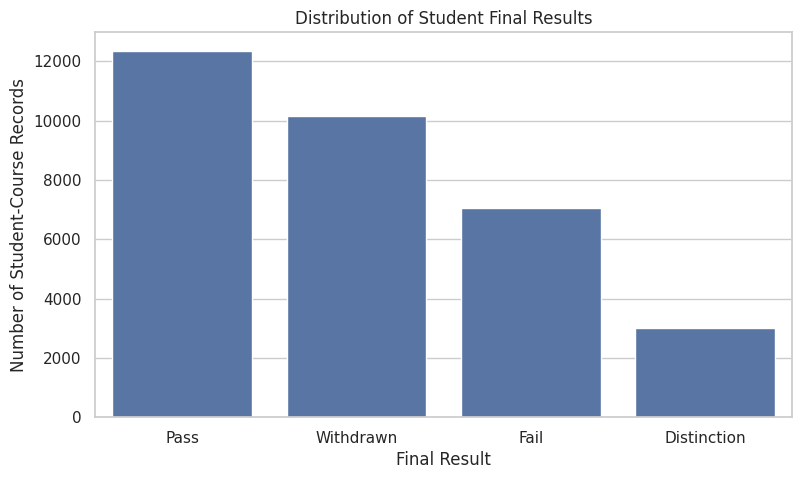

In [35]:

# STEP 29: Student Outcome Distribution

plt.figure(figsize=(9, 5))

sns.countplot(
    data=student_clean,
    x="final_result",
    order=student_clean["final_result"].value_counts().index
)

plt.title("Distribution of Student Final Results")
plt.xlabel("Final Result")
plt.ylabel("Number of Student-Course Records")

plt.show()


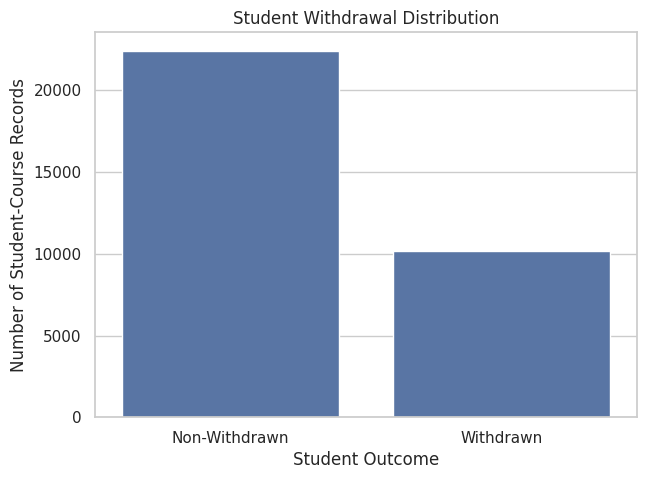

In [36]:

# STEP 30: Dropout Distribution

dropout_labels = student_clean["dropout"].map({
    0: "Non-Withdrawn",
    1: "Withdrawn"
})

plt.figure(figsize=(7, 5))

sns.countplot(x=dropout_labels)

plt.title("Student Withdrawal Distribution")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Student-Course Records")

plt.show()


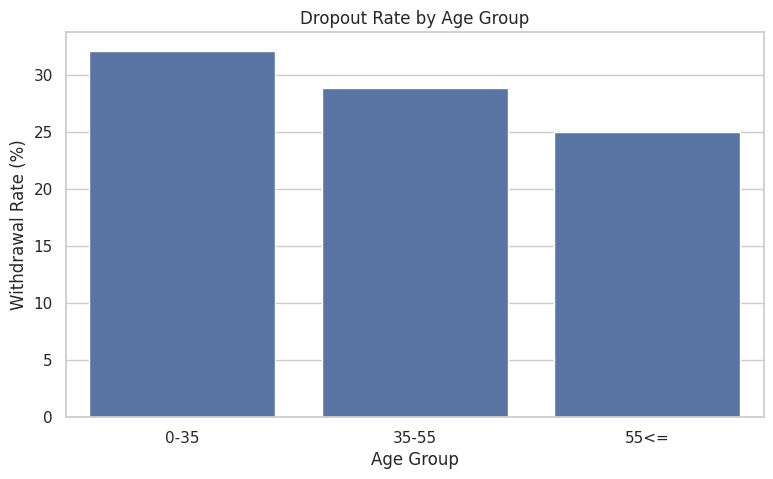

,Total_Records,Withdrawn,Dropout_Rate
age_band,,,
0-35,22944,7381,32.169630
35-55,9433,2721,28.845542
55<=,216,54,25.000000


In [37]:

# STEP 31: Dropout Rate by Age Group

age_analysis = (
    student_clean.groupby("age_band", observed=False)
    .agg(
        Total_Records=("id_student", "count"),
        Withdrawn=("dropout", "sum")
    )
)

age_analysis["Dropout_Rate"] = (
    age_analysis["Withdrawn"] /
    age_analysis["Total_Records"] * 100
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_analysis.reset_index(),
    x="age_band",
    y="Dropout_Rate"
)

plt.title("Dropout Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Withdrawal Rate (%)")

plt.show()

display(age_analysis)


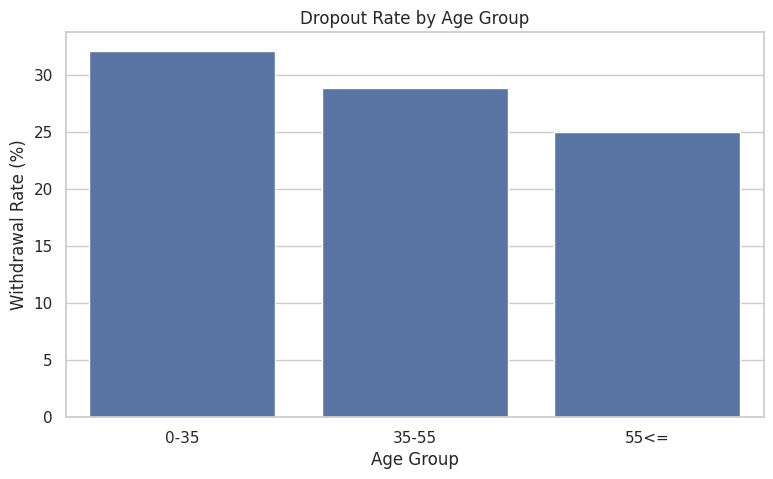

,Total_Records,Withdrawn,Dropout_Rate
age_band,,,
0-35,22944,7381,32.169630
35-55,9433,2721,28.845542
55<=,216,54,25.000000


In [38]:

# STEP 31: Dropout Rate by Age Group

age_analysis = (
    student_clean.groupby("age_band", observed=False)
    .agg(
        Total_Records=("id_student", "count"),
        Withdrawn=("dropout", "sum")
    )
)

age_analysis["Dropout_Rate"] = (
    age_analysis["Withdrawn"] /
    age_analysis["Total_Records"] * 100
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_analysis.reset_index(),
    x="age_band",
    y="Dropout_Rate"
)

plt.title("Dropout Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Withdrawal Rate (%)")

plt.show()

display(age_analysis)


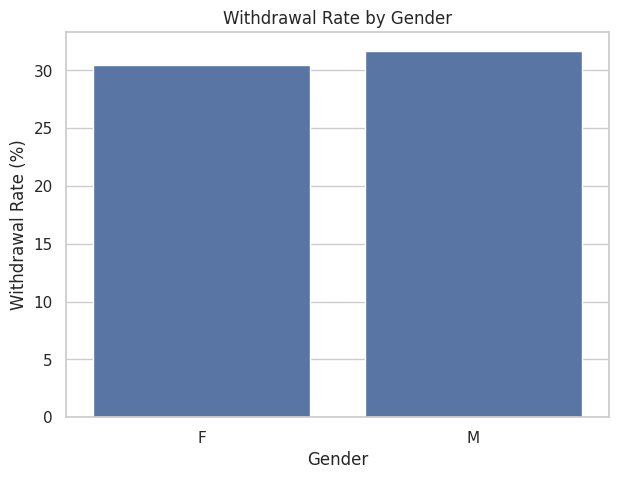

,Total_Records,Withdrawn,Dropout_Rate
gender,,,
F,14718,4486,30.479685
M,17875,5670,31.720280


In [39]:

# STEP 32: Gender-wise Dropout Analysis

gender_analysis = (
    student_clean.groupby("gender")
    .agg(
        Total_Records=("id_student", "count"),
        Withdrawn=("dropout", "sum")
    )
)

gender_analysis["Dropout_Rate"] = (
    gender_analysis["Withdrawn"] /
    gender_analysis["Total_Records"] * 100
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=gender_analysis.reset_index(),
    x="gender",
    y="Dropout_Rate"
)

plt.title("Withdrawal Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Withdrawal Rate (%)")

plt.show()

display(gender_analysis)


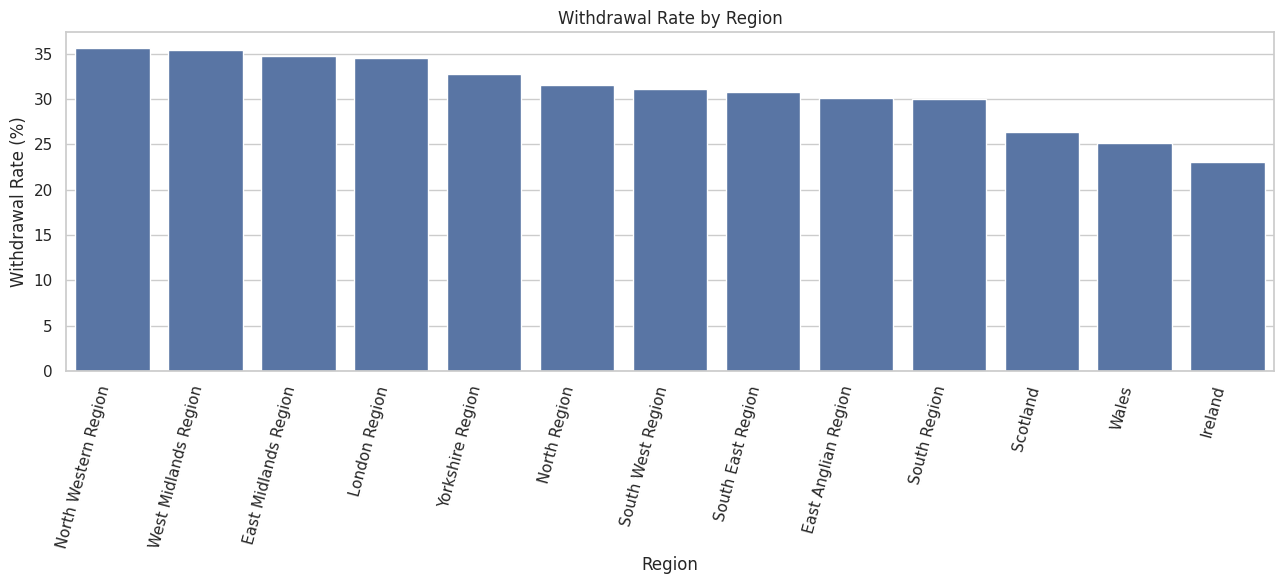

In [40]:

# STEP 33: Region-wise Dropout Analysis

region_analysis = (
    student_clean.groupby("region")
    .agg(
        Total_Records=("id_student", "count"),
        Withdrawn=("dropout", "sum")
    )
)

region_analysis["Dropout_Rate"] = (
    region_analysis["Withdrawn"] /
    region_analysis["Total_Records"] * 100
)

region_analysis = region_analysis.sort_values(
    "Dropout_Rate",
    ascending=False
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=region_analysis.reset_index(),
    x="region",
    y="Dropout_Rate"
)

plt.title("Withdrawal Rate by Region")
plt.xlabel("Region")
plt.ylabel("Withdrawal Rate (%)")
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()


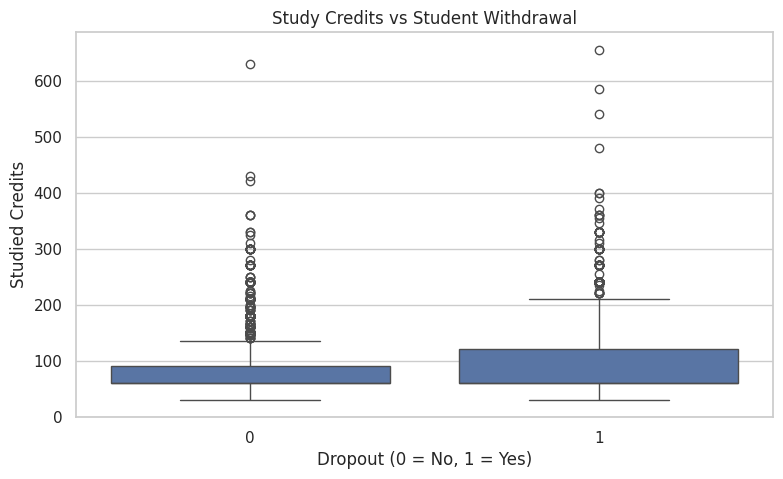

In [41]:

# STEP 34: Study Credits Analysis

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=student_clean,
    x="dropout",
    y="studied_credits"
)

plt.title("Study Credits vs Student Withdrawal")
plt.xlabel("Dropout (0 = No, 1 = Yes)")
plt.ylabel("Studied Credits")

plt.show()


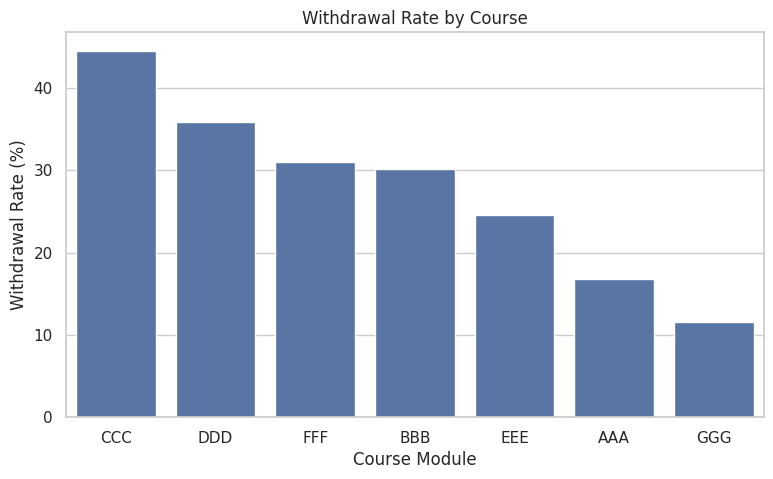

,Total_Records,Withdrawn,Dropout_Rate
code_module,,,
CCC,4434,1975,44.542174
DDD,6272,2250,35.873724
FFF,7762,2403,30.958516
BBB,7909,2388,30.193450
EEE,2934,722,24.608044
AAA,748,126,16.844920
GGG,2534,292,11.523283


In [42]:

# STEP 35: Course-wise Dropout Analysis

course_analysis = (
    student_clean.groupby("code_module")
    .agg(
        Total_Records=("id_student", "count"),
        Withdrawn=("dropout", "sum")
    )
)

course_analysis["Dropout_Rate"] = (
    course_analysis["Withdrawn"] /
    course_analysis["Total_Records"] * 100
)

course_analysis = course_analysis.sort_values(
    "Dropout_Rate",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=course_analysis.reset_index(),
    x="code_module",
    y="Dropout_Rate"
)

plt.title("Withdrawal Rate by Course")
plt.xlabel("Course Module")
plt.ylabel("Withdrawal Rate (%)")

plt.show()

display(course_analysis)


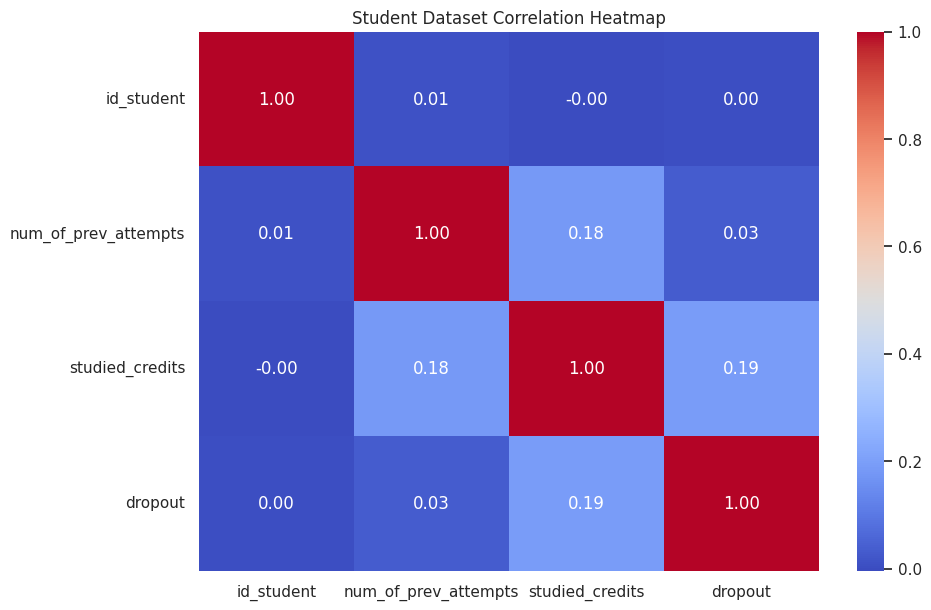

In [43]:

# STEP 36: Correlation Heatmap

numerical_data = student_clean.select_dtypes(
    include=["int64", "float64"]
)

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Dataset Correlation Heatmap")

plt.show()


In [44]:

# STEP 37: Save EDA analysis tables

age_analysis.to_csv(
    "/content/eda_age_analysis.csv"
)

gender_analysis.to_csv(
    "/content/eda_gender_analysis.csv"
)

region_analysis.to_csv(
    "/content/eda_region_analysis.csv"
)

course_analysis.to_csv(
    "/content/eda_course_analysis.csv"
)

print("EDA analysis tables saved successfully!")


EDA analysis tables saved successfully!


In [45]:

# STEP 38: Statistical Analysis

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

print("Statistical libraries imported successfully!")


Statistical libraries imported successfully!


In [46]:

# STEP 39: Create student-level analysis dataset

student_level = (
    student_clean.groupby("id_student")
    .agg(
        gender=("gender", "first"),
        dropout=("dropout", "max"),
        gender_categories=("gender", "nunique")
    )
    .reset_index()
)

# Keep students with a consistent gender value
student_level = student_level[
    student_level["gender_categories"] == 1
].copy()

# Exclude unknown gender for this comparison
student_level = student_level[
    student_level["gender"].notna() &
    (student_level["gender"] != "Unknown")
].copy()

print("Unique students:", len(student_level))

print("\nGender distribution:")
print(student_level["gender"].value_counts())

print("\nStudent-level withdrawal distribution:")
print(student_level["dropout"].value_counts())

display(student_level.head())


Unique students: 28785

Gender distribution:
gender
M    15046
F    13739
Name: count, dtype: int64

Student-level withdrawal distribution:
dropout
0    19630
1     9155
Name: count, dtype: int64


,id_student,gender,dropout,gender_categories
0,3733,M,1,1
1,6516,M,0,1
2,8462,M,1,1
3,11391,M,0,1
4,23629,F,0,1


In [47]:

# STEP 40: Gender vs Withdrawal

contingency_table = pd.crosstab(
    student_level["gender"],
    student_level["dropout"]
)

contingency_table.columns = [
    "Non_Withdrawn",
    "Withdrawn"
]

print("CONTINGENCY TABLE")
display(contingency_table)

print("\nWithdrawal percentage by gender:")

gender_rates = (
    student_level.groupby("gender")["dropout"]
    .agg(["count", "sum", "mean"])
)

gender_rates.columns = [
    "Total_Students",
    "Withdrawn_Students",
    "Withdrawal_Rate"
]

gender_rates["Withdrawal_Rate"] *= 100

display(gender_rates.round(2))


CONTINGENCY TABLE


,Non_Withdrawn,Withdrawn
gender,,
F,9553,4186
M,10077,4969



Withdrawal percentage by gender:


,Total_Students,Withdrawn_Students,Withdrawal_Rate
gender,,,
F,13739,4186,30.47
M,15046,4969,33.03


In [48]:

# STEP 41: Chi-square test of independence

if contingency_table.shape[0] >= 2 and contingency_table.shape[1] >= 2:

    chi2, p_value, degrees_freedom, expected = (
        chi2_contingency(contingency_table)
    )

    print("CHI-SQUARE TEST RESULTS")

    print("Chi-square statistic:", round(chi2, 4))
    print("P-value:", round(p_value, 6))
    print("Degrees of freedom:", degrees_freedom)

    print("\nExpected frequencies:")
    display(
        pd.DataFrame(
            expected,
            index=contingency_table.index,
            columns=contingency_table.columns
        ).round(2)
    )

    if (expected < 5).any():
        print("\nWarning: Some expected frequencies are below 5.")
        print("Consider Fisher's exact test for a 2x2 table.")

    alpha = 0.05

    print("\nSTATISTICAL INTERPRETATION")

    if p_value < alpha:
        print("Reject the null hypothesis.")
        print("There is statistical evidence of an association.")
    else:
        print("Fail to reject the null hypothesis.")
        print("There is insufficient evidence of an association.")

else:
    print("Insufficient categories for the Chi-square test.")


CHI-SQUARE TEST RESULTS
Chi-square statistic: 21.537
P-value: 3e-06
Degrees of freedom: 1

Expected frequencies:


,Non_Withdrawn,Withdrawn
gender,,
F,9369.34,4369.66
M,10260.66,4785.34



STATISTICAL INTERPRETATION
Reject the null hypothesis.
There is statistical evidence of an association.


In [49]:

# STEP 42: Calculate Cramer's V

if contingency_table.shape[0] >= 2 and contingency_table.shape[1] >= 2:

    total = contingency_table.to_numpy().sum()

    minimum_dimension = min(contingency_table.shape) - 1

    cramers_v = np.sqrt(
        chi2 / (total * minimum_dimension)
    )

    print("Cramer's V:", round(cramers_v, 4))

    if cramers_v < 0.1:
        print("Interpretation: Very weak association.")
    elif cramers_v < 0.3:
        print("Interpretation: Weak association.")
    elif cramers_v < 0.5:
        print("Interpretation: Moderate association.")
    else:
        print("Interpretation: Strong association.")


Cramer's V: 0.0274
Interpretation: Very weak association.


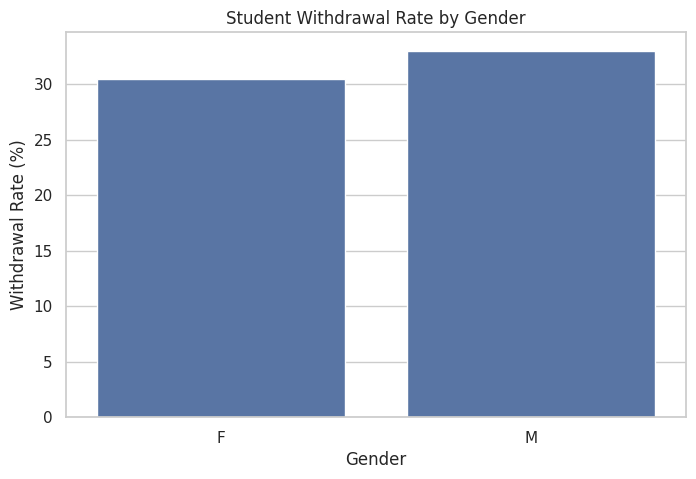

In [50]:

# STEP 43: Gender-wise withdrawal rate chart

gender_plot = gender_rates.reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_plot,
    x="gender",
    y="Withdrawal_Rate"
)

plt.title("Student Withdrawal Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Withdrawal Rate (%)")

plt.show()


In [51]:

# Step 44: Check dataset before machine learning

if "student_clean" not in globals():
    raise ValueError("student_clean is missing. Please run the data-cleaning cells first.")

required_columns = [
    "id_student",
    "code_module",
    "code_presentation",
    "final_result",
    "dropout"
]

missing_columns = [
    col for col in required_columns
    if col not in student_clean.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("Dataset is ready for machine learning!")
print("Dataset shape:", student_clean.shape)

print("\nDropout target distribution:")
print(student_clean["dropout"].value_counts())

print("\nDropout percentage:")
print(
    (student_clean["dropout"].value_counts(normalize=True) * 100)
    .round(2)
)


Dataset is ready for machine learning!
Dataset shape: (32593, 16)

Dropout target distribution:
dropout
0    22437
1    10156
Name: count, dtype: int64

Dropout percentage:
dropout
0    68.84
1    31.16
Name: proportion, dtype: float64


In [52]:

# Step 45: Baseline model and Logistic Regression

import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Copy dataset
ml_df = student_clean.copy()

# Keep rows with valid target and student ID
ml_df = ml_df.dropna(subset=["dropout", "id_student"])
ml_df["dropout"] = pd.to_numeric(ml_df["dropout"], errors="coerce")
ml_df = ml_df.dropna(subset=["dropout"])
ml_df = ml_df[ml_df["dropout"].isin([0, 1])]

# Features available at enrolment
possible_features = [
    "code_module",
    "code_presentation",
    "highest_education",
    "num_of_prev_attempts",
    "studied_credits"
]

features = [col for col in possible_features if col in ml_df.columns]

if not features:
    raise ValueError("No suitable prediction features found.")

X = ml_df[features]
y = ml_df["dropout"].astype(int)
groups = ml_df["id_student"]

# Split by student to reduce student-level data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

if y_train.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError(
        "The split contains only one target class in training or testing. "
        "Please share the target distribution."
    )

# Identify column types
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Baseline model
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

# Logistic Regression model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

# Compare results
results = pd.DataFrame({
    "Model": ["Dummy Baseline", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, logistic_predictions)
    ],
    "Precision": [
        precision_score(y_test, baseline_predictions, zero_division=0),
        precision_score(y_test, logistic_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, logistic_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, logistic_predictions, zero_division=0)
    ]
})

print("Features used:", features)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nModel Comparison:")
display(results.round(3))

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))


Features used: ['code_module', 'code_presentation', 'highest_education', 'num_of_prev_attempts', 'studied_credits']
Training rows: 26122
Testing rows: 6471

Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Dummy Baseline,0.698,0.000,0.000,0.000
1,Logistic Regression,0.609,0.403,0.614,0.487



Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.61      0.68      4516
           1       0.40      0.61      0.49      1955

    accuracy                           0.61      6471
   macro avg       0.59      0.61      0.59      6471
weighted avg       0.67      0.61      0.62      6471


Confusion Matrix:
[[2742 1774]
 [ 755 1200]]


In [53]:

# Step 46: Random Forest Model

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Check that the previous model-training cell has run
required_variables = ["X_train", "X_test", "y_train", "y_test"]

for variable in required_variables:
    if variable not in globals():
        raise ValueError(
            f"{variable} is missing. Run Step 45 first."
        )

# Prepare preprocessing
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

rf_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create Random Forest model
random_forest_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Make predictions
rf_predictions = random_forest_model.predict(X_test)

# Evaluate Random Forest
print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

# Compare all three models
comparison = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, baseline_predictions, zero_division=0),
        precision_score(y_test, logistic_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, logistic_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, logistic_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ]
})

print("\nFinal Model Comparison:")
display(comparison.round(3))


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.63      0.70      4516
           1       0.41      0.58      0.48      1955

    accuracy                           0.62      6471
   macro avg       0.59      0.61      0.59      6471
weighted avg       0.66      0.62      0.63      6471

Random Forest Confusion Matrix:
[[2858 1658]
 [ 824 1131]]

Final Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Dummy Baseline,0.698,0.000,0.000,0.000
1,Logistic Regression,0.609,0.403,0.614,0.487
2,Random Forest,0.616,0.406,0.579,0.477


RANDOM FOREST ADVANCED EVALUATION
--------------------------------
ROC-AUC Score: 0.6558
Precision-Recall AUC: 0.4434


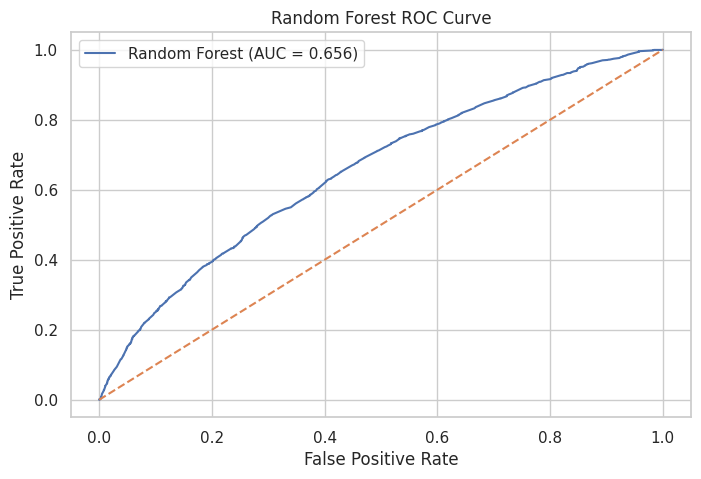

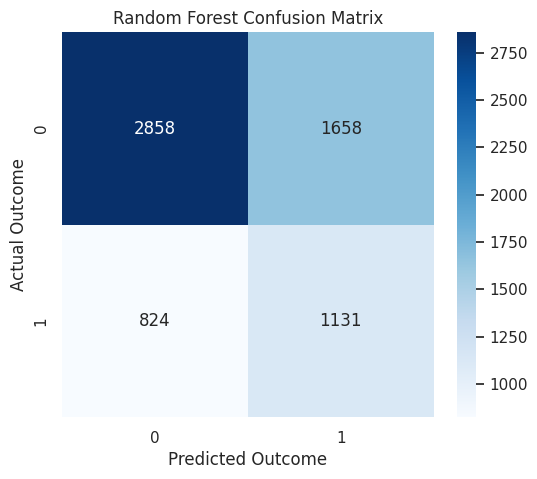

In [54]:

# STEP 47: Advanced Random Forest Evaluation

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc
)
import matplotlib.pyplot as plt
import seaborn as sns

# Predict dropout probabilities
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
roc_auc = roc_auc_score(y_test, rf_probabilities)

pr_auc = average_precision_score(
    y_test,
    rf_probabilities
)

print("RANDOM FOREST ADVANCED EVALUATION")
print("--------------------------------")
print("ROC-AUC Score:", round(roc_auc, 4))
print("Precision-Recall AUC:", round(pr_auc, 4))

# ROC Curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    rf_probabilities
)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("Random Forest ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.show()


TOP 15 IMPORTANT FEATURES


,Feature,Importance
1,num__studied_credits,0.416409
8,cat__code_module_GGG,0.110700
4,cat__code_module_CCC,0.097017
15,cat__highest_education_Lower Than A Level,0.061268
0,num__num_of_prev_attempts,0.059605
5,cat__code_module_DDD,0.031249
12,cat__code_presentation_2014J,0.028588
14,cat__highest_education_HE Qualification,0.024271
13,cat__highest_education_A Level or Equivalent,0.023456
10,cat__code_presentation_2013J,0.020723


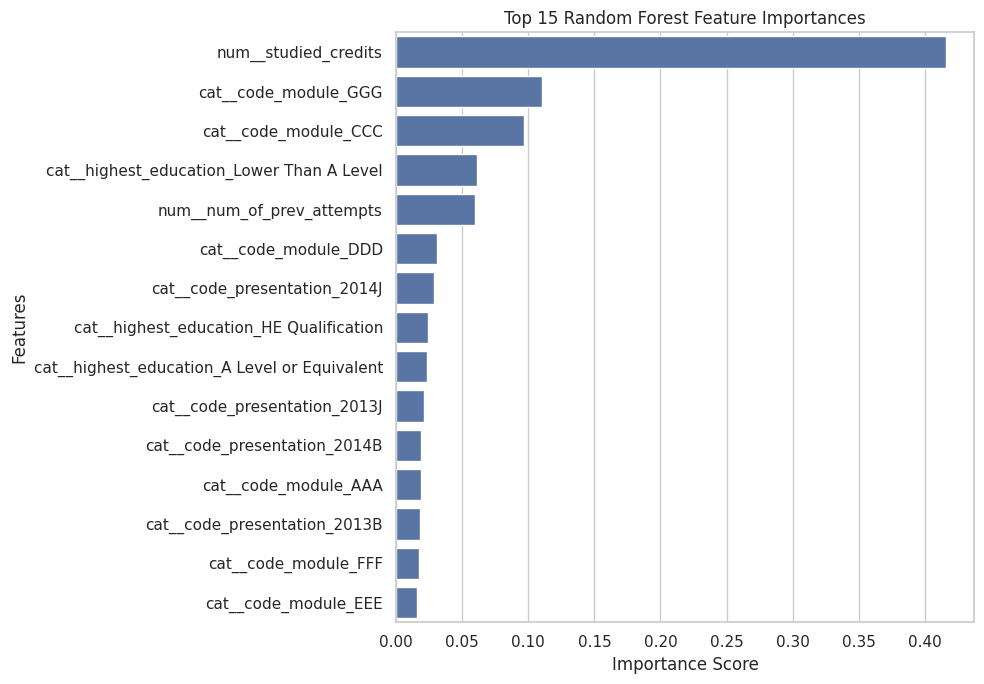

In [55]:

# STEP 48: Feature Importance

rf_classifier = random_forest_model.named_steps["classifier"]

rf_preprocessor = random_forest_model.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")

display(feature_importance.head(15))

# Visualize top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


In [56]:

# STEP 49: Save Random Forest Model

import joblib

model_path = "/content/student_dropout_random_forest.pkl"

joblib.dump(random_forest_model, model_path)

print("Random Forest model saved successfully!")
print("File:", model_path)


Random Forest model saved successfully!
File: /content/student_dropout_random_forest.pkl


In [57]:
import pandas as pd
from scipy.stats import chi2_contingency
import numpy as np

# Check required columns
required = ["num_of_prev_attempts", "dropout"]

missing = [col for col in required if col not in student_clean.columns]

if missing:
    raise KeyError(f"Missing columns: {missing}")

# Prepare data
test_df = student_clean[required].dropna().copy()

# Convert previous attempts into categories
test_df["previous_attempts"] = (
    test_df["num_of_prev_attempts"].astype(str)
)

# Create contingency table
table = pd.crosstab(
    test_df["previous_attempts"],
    test_df["dropout"]
)

print("Contingency Table:")
display(table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(table)

# Calculate Cramer's V
n = table.to_numpy().sum()
minimum_dimension = min(table.shape) - 1

cramers_v = (
    np.sqrt(chi2 / (n * minimum_dimension))
    if minimum_dimension > 0 else np.nan
)

print("\nChi-square Statistic:", round(chi2, 3))
print("P-value:", p_value)
print("Degrees of Freedom:", dof)
print("Cramer's V:", round(cramers_v, 3))

# Interpretation
if p_value < 0.05:
    print("\nResult: Reject the null hypothesis.")
    print("There is a statistically significant association.")
else:
    print("\nResult: Fail to reject the null hypothesis.")
    print("There is no statistically significant association.")

Contingency Table:


dropout,0,1
previous_attempts,,
0,19736,8685
1,2149,1150
2,428,247
3,89,53
4,25,14
5,8,5
6,2,2



Chi-square Statistic: 39.035
P-value: 7.046967414214444e-07
Degrees of Freedom: 6
Cramer's V: 0.035

Result: Reject the null hypothesis.
There is a statistically significant association.


In [58]:
# Check whether studentVle is available
if "studentVle" in datasets:
    vle_df = datasets["studentVle"].copy()
    print("studentVle dataset found!")
    print("Shape:", vle_df.shape)
    print("\nColumns:")
    print(vle_df.columns.tolist())
    display(vle_df.head())
else:
    print("studentVle dataset is not loaded.")
    print("Available datasets:", list(datasets.keys()))

studentVle dataset is not loaded.
Available datasets: ['assessments', 'studentInfo']


In [60]:
import os
import glob
import pandas as pd

# Find the OULAD studentVle.csv file
matches = glob.glob(
    "/content/**/studentVle.csv",
    recursive=True
)

print("Files found:", matches)

if not matches:
    raise FileNotFoundError(
        "studentVle.csv not found. Check your OULAD ZIP extraction."
    )

# Load the dataset
student_vle_file = matches[0]
vle_df = pd.read_csv(student_vle_file)

# Store it in the datasets dictionary
datasets["studentVle"] = vle_df

print("\nDataset loaded successfully!")
print("Shape:", vle_df.shape)
print("Columns:", vle_df.columns.tolist())

display(vle_df.head())

Files found: ['/content/studentVle.csv']

Dataset loaded successfully!
Shape: (10655280, 6)
Columns: ['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


Weekly Activity Summary:


,week,sum_click
0,-4,43298
1,-3,433407
2,-2,646001
3,-1,1025241
4,0,2013077
5,1,1797648
6,2,2307080
7,3,1663598
8,4,1505334
9,5,1228901


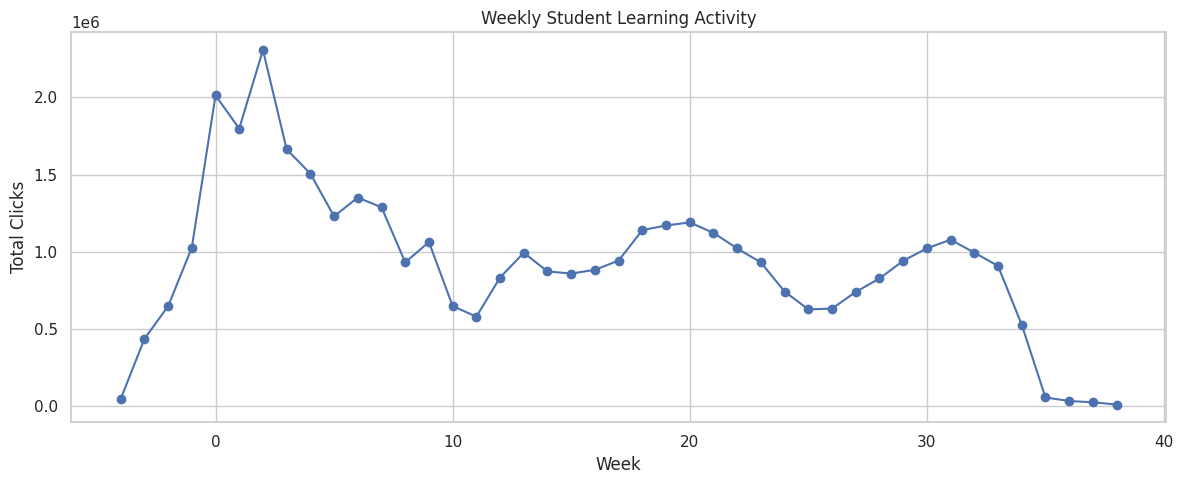

In [61]:
import pandas as pd
import matplotlib.pyplot as plt

# Check whether the dataset is loaded
if "vle_df" not in globals():
    raise NameError("Run the studentVle loading cell first.")

# Select required columns
activity_df = vle_df[["date", "sum_click"]].copy()

# Clean data
activity_df["date"] = pd.to_numeric(
    activity_df["date"], errors="coerce"
)

activity_df["sum_click"] = pd.to_numeric(
    activity_df["sum_click"], errors="coerce"
)

activity_df = activity_df.dropna()

# Group activity by week
activity_df["week"] = (
    activity_df["date"] // 7
).astype(int)

weekly_activity = (
    activity_df.groupby("week")["sum_click"]
    .sum()
    .reset_index()
)

# Display results
print("Weekly Activity Summary:")
display(weekly_activity.head(15))

# Visualize weekly activity
plt.figure(figsize=(12, 5))
plt.plot(
    weekly_activity["week"],
    weekly_activity["sum_click"],
    marker="o"
)

plt.title("Weekly Student Learning Activity")
plt.xlabel("Week")
plt.ylabel("Total Clicks")
plt.grid(True)
plt.tight_layout()
plt.show()

Withdrawal Analysis by Age Group:


,age_category,Total_Students,Withdrawals,Withdrawal_Rate
0,0-35,22944,7381,32.169630
1,35-55,9433,2721,28.845542
2,55<=,216,54,25.000000


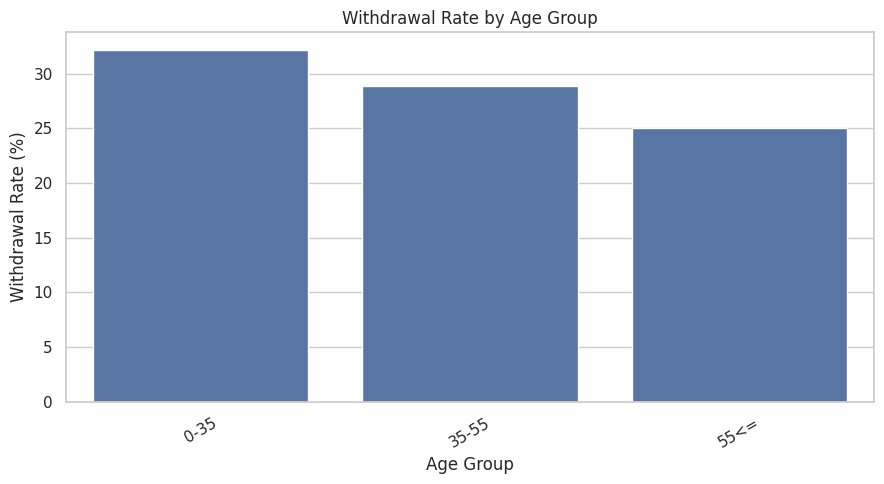


Group with highest withdrawal rate:
age_category           0-35
Total_Students        22944
Withdrawals            7381
Withdrawal_Rate    32.16963
Name: 0, dtype: object


In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check required columns
required = ["age_category", "dropout"]

missing = [
    col for col in required
    if col not in student_clean.columns
]

if missing:
    raise KeyError(f"Missing columns: {missing}")

# Calculate withdrawal rate by age group
age_analysis = (
    student_clean.groupby("age_category")
    .agg(
        Total_Students=("dropout", "count"),
        Withdrawals=("dropout", "sum"),
        Withdrawal_Rate=("dropout", "mean")
    )
    .reset_index()
)

age_analysis["Withdrawal_Rate"] *= 100

print("Withdrawal Analysis by Age Group:")
display(age_analysis)

# Visualize withdrawal rates
plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_analysis,
    x="age_category",
    y="Withdrawal_Rate"
)

plt.title("Withdrawal Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Withdrawal Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Identify the group with the highest withdrawal rate
highest_group = age_analysis.loc[
    age_analysis["Withdrawal_Rate"].idxmax()
]

print("\nGroup with highest withdrawal rate:")
print(highest_group)

In [63]:
# Generate recommendations based on withdrawal rates

recommendations = []

for _, row in age_analysis.iterrows():

    group = row["age_category"]
    rate = row["Withdrawal_Rate"]
    total = row["Total_Students"]

    if rate >= 40:
        action = "Provide priority academic support and regular mentoring."
    elif rate >= 25:
        action = "Provide additional learning resources and progress monitoring."
    else:
        action = "Continue existing student support and monitor progress."

    recommendations.append({
        "Age Group": group,
        "Total Students": total,
        "Withdrawal Rate (%)": round(rate, 2),
        "Recommended Action": action
    })

recommendation_df = pd.DataFrame(recommendations)

print("Student Support Recommendations:")
display(recommendation_df)

# Save recommendations
recommendation_df.to_csv(
    "/content/student_support_recommendations.csv",
    index=False
)

print("Recommendations saved successfully!")

Student Support Recommendations:


,Age Group,Total Students,Withdrawal Rate (%),Recommended Action
0,0-35,22944,32.17,Provide additional learning resources and prog...
1,35-55,9433,28.85,Provide additional learning resources and prog...
2,55<=,216,25.00,Provide additional learning resources and prog...


Recommendations saved successfully!


In [64]:
import pandas as pd

# Overall project KPIs
total_records = len(student_clean)
total_withdrawals = student_clean["dropout"].sum()

overall_withdrawal_rate = (
    total_withdrawals / total_records
) * 100 if total_records > 0 else 0

# Create KPI summary
dashboard_kpis = pd.DataFrame({
    "Metric": [
        "Total Student-Course Records",
        "Total Withdrawals",
        "Overall Withdrawal Rate (%)"
    ],
    "Value": [
        total_records,
        total_withdrawals,
        round(overall_withdrawal_rate, 2)
    ]
})

print("Dashboard KPI Summary:")
display(dashboard_kpis)

# Save dashboard data
dashboard_kpis.to_csv(
    "/content/dashboard_kpis.csv",
    index=False
)

age_analysis.to_csv(
    "/content/dashboard_age_analysis.csv",
    index=False
)

weekly_activity.to_csv(
    "/content/dashboard_weekly_activity.csv",
    index=False
)

print("Dashboard datasets saved successfully!")

Dashboard KPI Summary:


,Metric,Value
0,Total Student-Course Records,32593.00
1,Total Withdrawals,10156.00
2,Overall Withdrawal Rate (%),31.16


Dashboard datasets saved successfully!


In [65]:
from datetime import datetime

report = f"""
# Student Performance & Dropout Risk Analytics:
## Integrated Decision Analysis and Responsible Reporting

### 1. Project Overview
This project analyzes student performance and withdrawal patterns
using the Open University Learning Analytics Dataset (OULAD).

### 2. Project Objectives
- Analyze student academic performance.
- Identify student withdrawal patterns.
- Explore learning activity trends.
- Build a machine learning classification model.
- Develop data-driven student support recommendations.

### 3. Dataset Information
Dataset: Open University Learning Analytics Dataset (OULAD)
Source: UCI Machine Learning Repository

The analysis uses student-course records and learning activity data.
The outcome category Withdrawn is treated as the withdrawal target.

### 4. Data Preparation
- Checked missing values.
- Identified duplicate records.
- Cleaned categorical and numerical fields.
- Created a binary withdrawal target.
- Engineered age and study-credit categories.

### 5. Exploratory Data Analysis
The project examined:
- Final result distribution.
- Withdrawal distribution.
- Age group distribution.
- Gender distribution.
- Region distribution.
- Study credits.
- Course distribution.
- Correlation between numerical variables.

### 6. Statistical Analysis
A Chi-square test was used to examine the association between
previous attempts and withdrawal outcomes.

### 7. Machine Learning
Model: Random Forest Classifier

Evaluation methods:
- Classification report.
- Confusion matrix.
- ROC-AUC.
- Precision and recall.
- Comparison with baseline models.

### 8. Learning Activity Analysis
Daily learning-platform clicks were grouped into weekly totals
to study changes in student activity over time.

### 9. Decision Analysis
Withdrawal rates were compared across age groups.
Support recommendations were generated based on observed rates.

### 10. Responsible Analytics
- Withdrawal patterns do not establish causation.
- Student-course records are not unique student counts.
- Sensitive attributes should be handled carefully.
- Model predictions should support, not replace, human decisions.
- Prediction quality and fairness should be evaluated before deployment.

### 11. Conclusion
This project demonstrates how educational data analytics,
statistical testing, machine learning, and decision analysis
can help institutions understand student withdrawal patterns
and investigate opportunities for academic support.

### 12. Dataset Limitation
The target represents withdrawal from a course presentation.
It should not automatically be interpreted as permanent
withdrawal from higher education.

Report generated: {datetime.now().strftime("%Y-%m-%d")}
"""

with open("/content/final_project_report.md", "w") as file:
    file.write(report)

print("Final project report created successfully!")
print(report)

Final project report created successfully!

# Student Performance & Dropout Risk Analytics:
## Integrated Decision Analysis and Responsible Reporting

### 1. Project Overview
This project analyzes student performance and withdrawal patterns
using the Open University Learning Analytics Dataset (OULAD).

### 2. Project Objectives
- Analyze student academic performance.
- Identify student withdrawal patterns.
- Explore learning activity trends.
- Build a machine learning classification model.
- Develop data-driven student support recommendations.

### 3. Dataset Information
Dataset: Open University Learning Analytics Dataset (OULAD)
Source: UCI Machine Learning Repository

The analysis uses student-course records and learning activity data.
The outcome category Withdrawn is treated as the withdrawal target.

### 4. Data Preparation
- Checked missing values.
- Identified duplicate records.
- Cleaned categorical and numerical fields.
- Created a binary withdrawal target.
- Engineered age an

In [66]:
import os
import zipfile

# Create project folder
project_folder = "/content/Student_Performance_Analytics"
os.makedirs(project_folder, exist_ok=True)

# Files to include
files_to_save = [
    "final_project_report.md",
    "student_support_recommendations.csv",
    "dashboard_kpis.csv",
    "dashboard_age_analysis.csv",
    "dashboard_weekly_activity.csv",
    "student_dropout_random_forest.pkl"
]

# Copy available files
import shutil

for filename in files_to_save:
    source = f"/content/{filename}"

    if os.path.exists(source):
        shutil.copy(source, project_folder)
        print("Added:", filename)
    else:
        print("Not found:", filename)

# Create ZIP file
zip_path = "/content/Student_Performance_Analytics.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(project_folder):
        for file in files:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(full_path, project_folder)
            zipf.write(full_path, relative_path)

print("\nProject ZIP created:", zip_path)

Added: final_project_report.md
Added: student_support_recommendations.csv
Added: dashboard_kpis.csv
Added: dashboard_age_analysis.csv
Added: dashboard_weekly_activity.csv
Added: student_dropout_random_forest.pkl

Project ZIP created: /content/Student_Performance_Analytics.zip


In [67]:
from google.colab import files

files.download("/content/Student_Performance_Analytics.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>